## AC 20
This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.dysanos.grid.interpolated
%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_model_static
%aimport quantdata.dysanos.grid.torch_model_pca
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 

from quantdata.dysanos.grid.torch_market import GridMarketDefinition, DateRange, PoolConfig, Context, date, GridConfig

grid_config     = GridConfig(grid_num_strikes=100)
grid_market_def = GridMarketDefinition( ticker="SPX", date_range=DateRange(start=date(2020, 1, 1), end=date(2025, 8, 30)), grid_config=grid_config )
market          = grid_market_def.load( pool_config = PoolConfig(num_workers=4, threading=False ), verbose=Context.all )
print(f"nms /done - found {len(market['dates'])} dates.")
    

nms /done - found 1412 dates.


00: Training 20-ac-SELU-sqrtVar version 0.3 group 'sm25_100' for 100000 epochs on SPX for date range 2020-01-01_2025-08-30x
00: Using batches of 400 samples with learning rate 0.0001 and weight decay 0.0001.
01:   Model config: 20-ac-SELU-sqrtVar.sm25_100 0.3 0.25-smooth sample,mvsq=0.0001 nms=20,(-2.00,1.00) dlv=(0.01,3.00),fvol=(0.01,2.00) state=20@FF(d=2,w=100,a=SELU,b=True),lrn=FF(d=2,w=100,a=SELU,b=True)
01:   Grid config: nms,rg=(-2,1),nm=100,xp=(2.0,4.9,9.9,19.8,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2,msqv=0.0001
01:   Mk Arb Free pre-processor: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
00: Preparing data set 20-ac-SELU-sqrtVar version 0.3 on Env(prec=32,device=cuda,debug=False)... done; this took 3s.
00: Instantiating 20-ac-SELU-sqrtVar versio

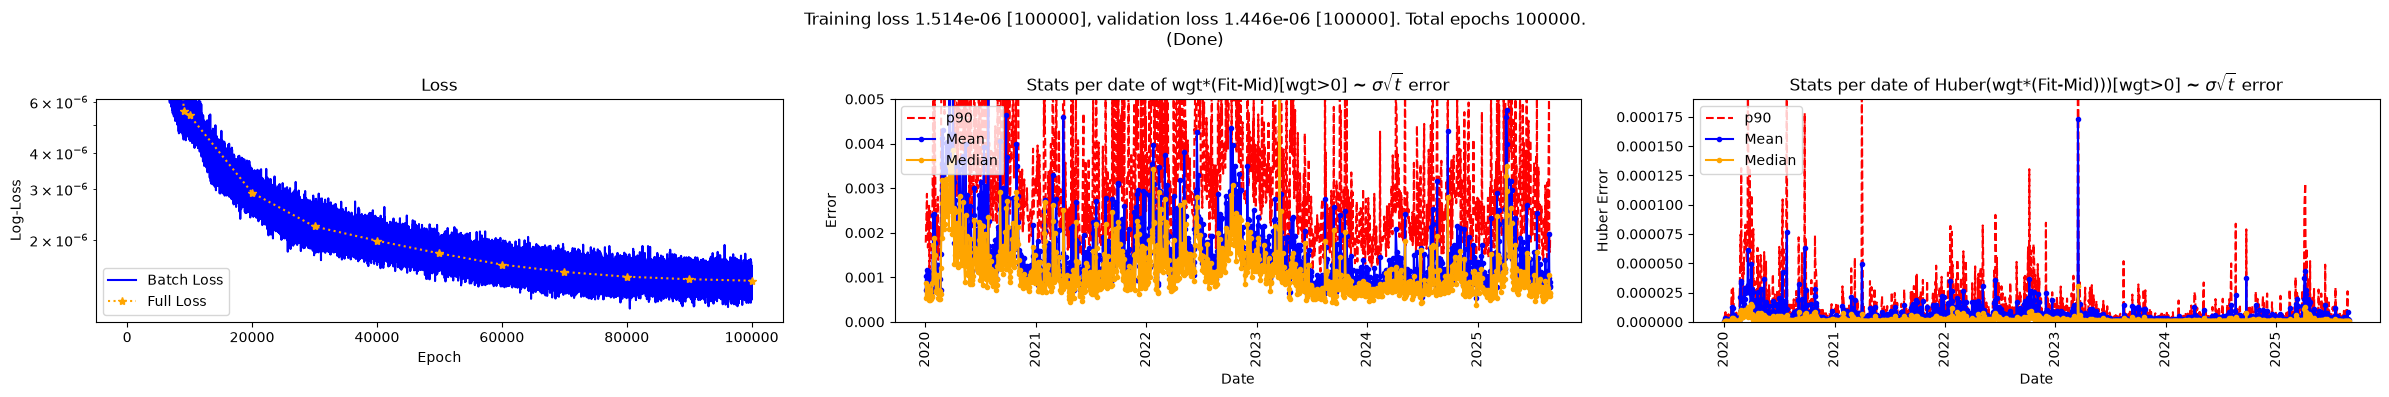

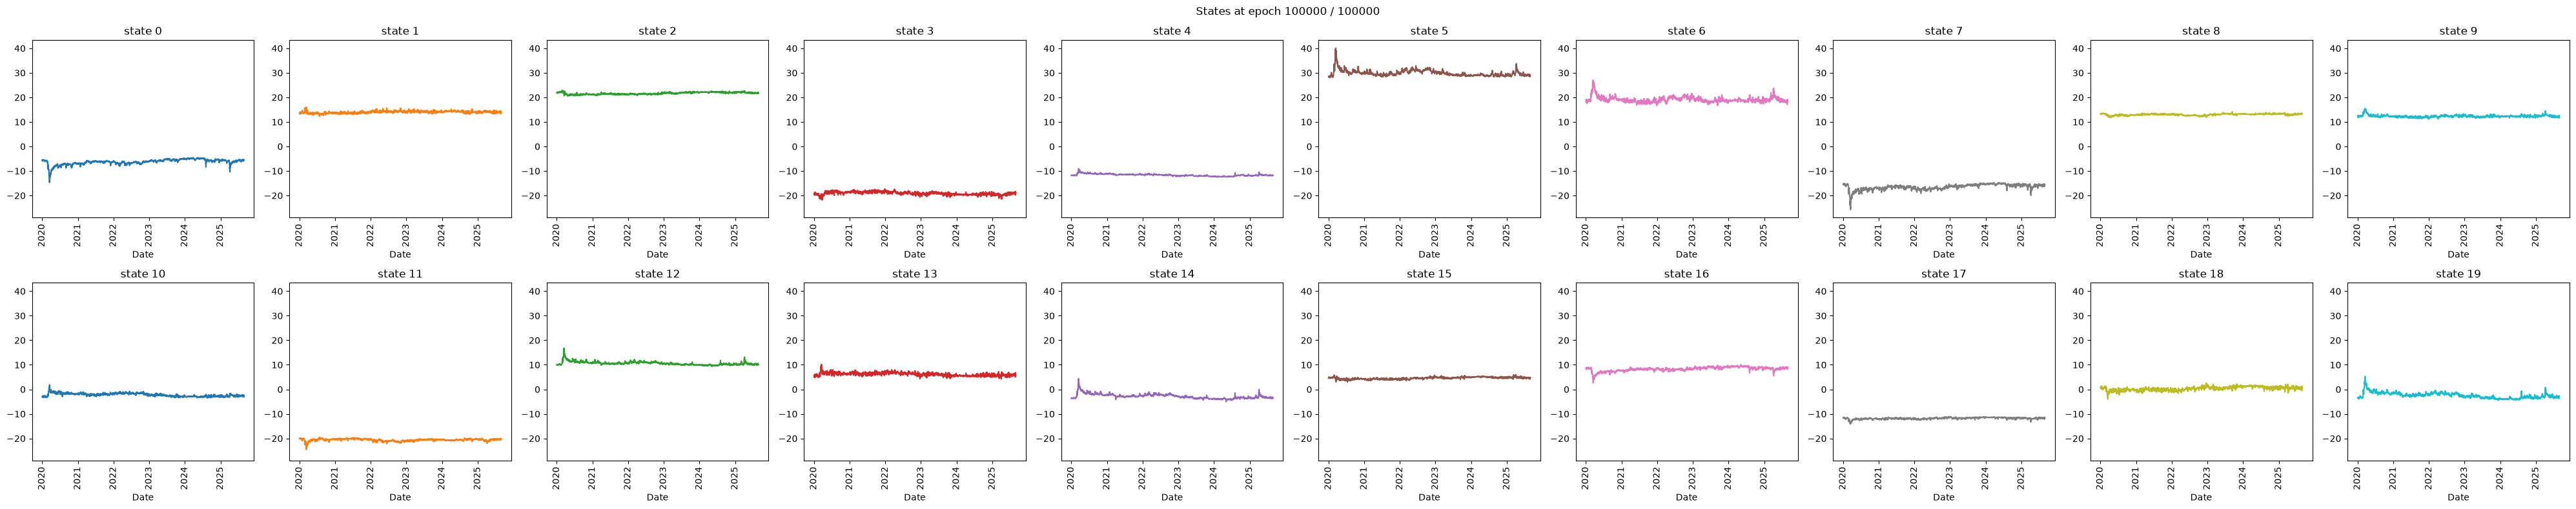

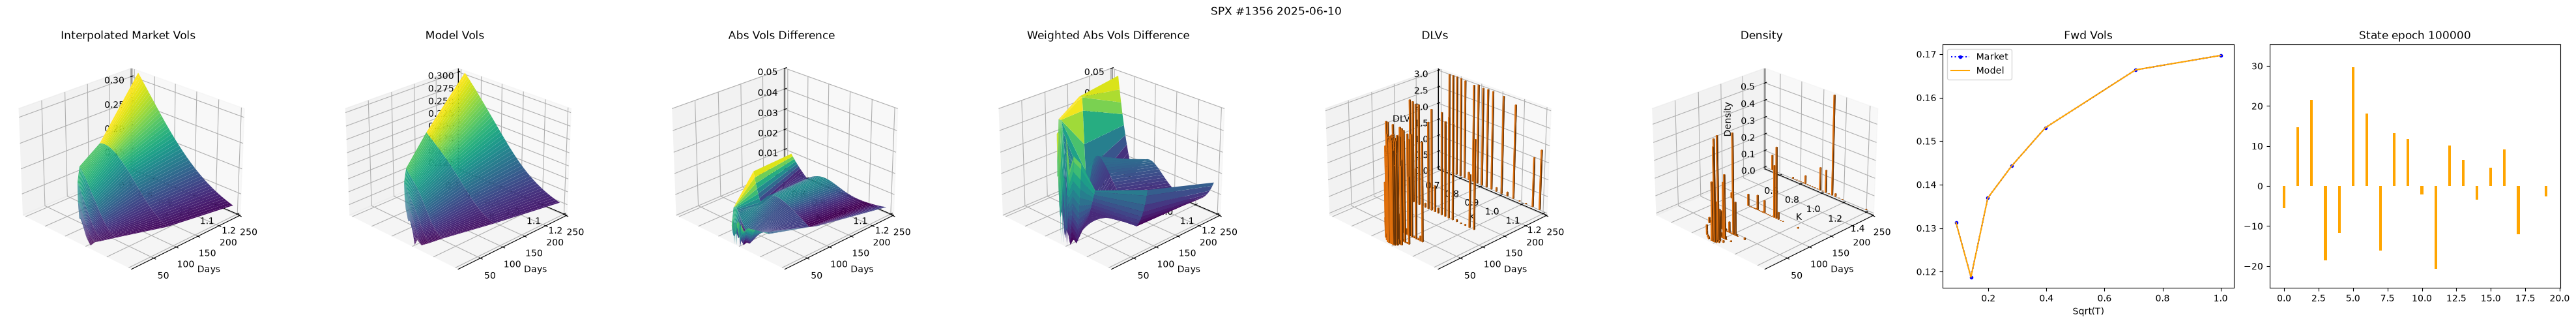

/home/hans/vqdata/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
/home/hans/vqdata/lib/python3.13/site-packages/mpl_toolkits/mplot3d/proj3d.py:184: RuntimeWarning: overflow encountered in dot


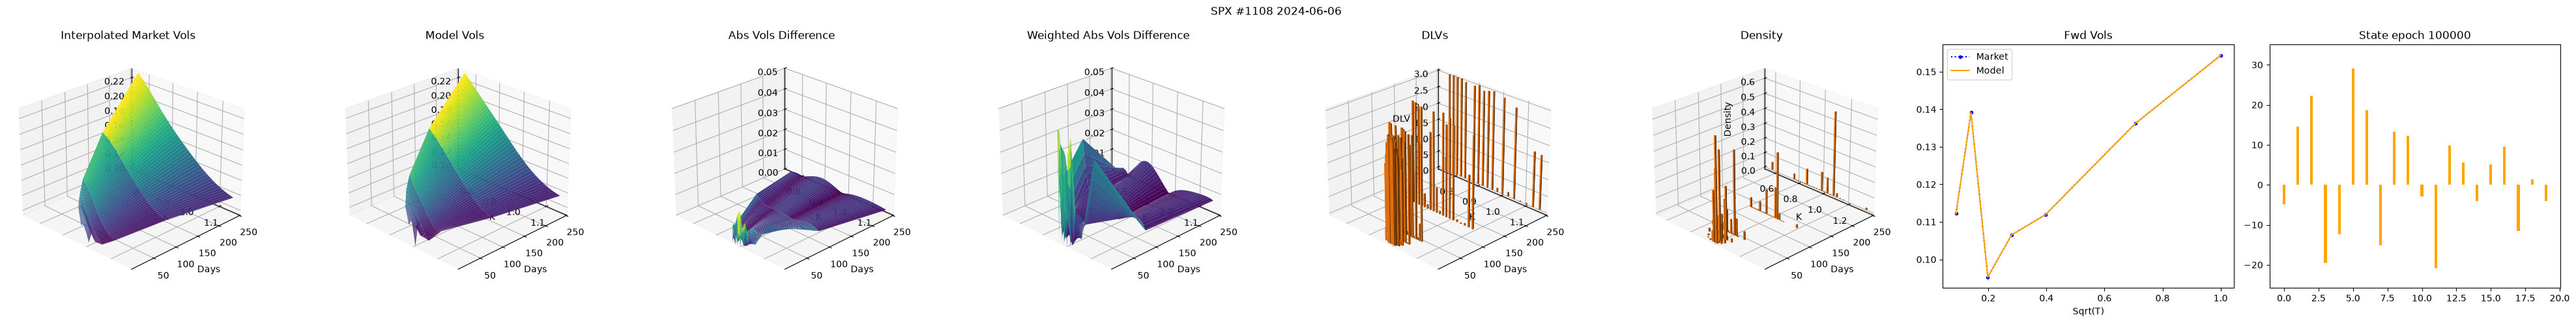

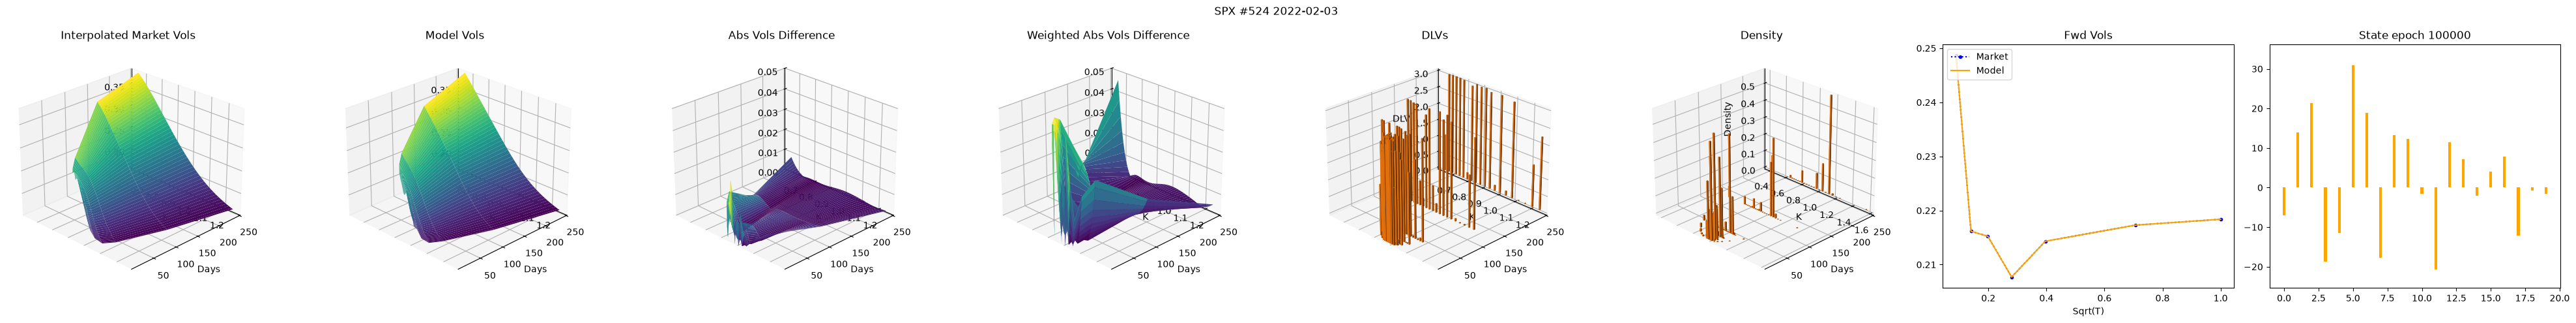

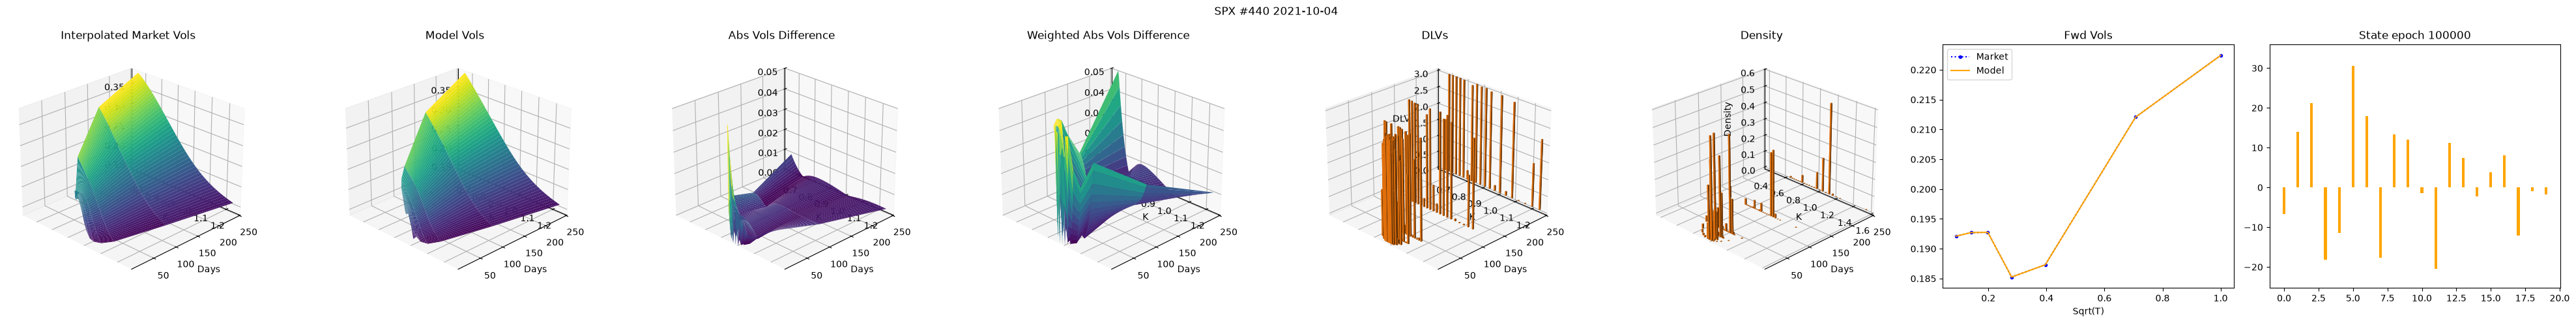

00: Training 20-ac-SELU-sqrtVar.sm25_100 0.3 0.25-smooth sample,mvsq=0.0001 nms=20,(-2.00,1.00) dlv=(0.01,3.00),fvol=(0.01,2.00) state=20@FF(d=2,w=100,a=SELU,b=True),lrn=FF(d=2,w=100,a=SELU,b=True) with epochs=100000,lr=0.0001->1e-06,wdec=0.0001,bsize=400 on Env(prec=32,device=cuda,debug=False):


/home/hans/vqdata/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


00: Model trained for 100000 epochs. This took 2:56.                                                             
00: Model 20-ac-SELU-sqrtVar version 0.3 group 'sm25_100' trained for 100000 epochs. Final training loss: 1.514e-06, valuation loss: 1.446e-06. This took 3:01.
00: Checkpoint file is /home/hans/.dysanos_grid/sm25_100/20-ac-SELU-sqrtVar a83962b6.pt.
/done


In [2]:
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.pool import PoolConfig
from quantdata.dysanos.grid.torch_gfx import VizConfig
from quantdata.dysanos.grid.torch_train import train, TrainConfig
from quantdata.dysanos.grid.torch_model_static import BaseEnvironment, FeedForward, SanosCompressorConfig
import numpy as np

# note: convergence blows up.
mdl_config = SanosCompressorConfig( 
    user_version="0.2",
    group="sm25_100",
    smoothness = 0.25,
    num_state = 20, 
    state_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
    learn_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
    _debug_dont_learn_sqrtVars = True
)

viz_config = VizConfig( num_viz_dates=4 )
trn_config = TrainConfig( num_epochs=100_000, lr=1E-4, final_lr=1E-6, weight_decay=1e-4, batch_size=400, compile=True, epoch_interval=10000 )
r, model, tdata = train( market, mdl_config=mdl_config, trn_config=trn_config, viz_config=viz_config )
print("/done")
